# Lopes et al. (2025): reproduction notebook

This notebook follows the paper's order. It presents only checked-in computed outputs or explicitly labelled published references; missing analysis is never filled with publication targets. See [`REPORT.md`](../REPORT.md) for the claim-by-claim audit.

## Parameters and run mode

`reference` is the offline default and reads only `reference/`. `reduced` launches the README's exploratory pipeline settings and downloads data. `full` reads a completed `gastric-repro run` output directory and never launches it. The full run can take many hours and must be run separately.

In [1]:
from pathlib import Path
import subprocess
import sys

RUN_MODE = "reference"  # one of: reference, reduced, full
RESULTS_DIR = Path("results")
PUBLISHED_SALIVA_RESULTS_DIR = Path("results-saliva-published")
EXPORT_FIGURES = False

BASE = Path.cwd().resolve()
if not (BASE / "reference").is_dir() and (BASE.parent / "reference").is_dir():
    BASE = BASE.parent
REFERENCE_DIR = BASE / "reference"
if RUN_MODE not in {"reference", "reduced", "full"}:
    raise ValueError("RUN_MODE must be reference, reduced, or full")

RESULTS_DIR = (BASE / RESULTS_DIR).resolve()
PUBLISHED_SALIVA_RESULTS_DIR = (BASE / PUBLISHED_SALIVA_RESULTS_DIR).resolve()
if RUN_MODE == "reduced":
    RESULTS_DIR = BASE / "results-exploratory"
    subprocess.run([
        sys.executable, "-m", "gastric_repro.cli", "run",
        "--cache", str(BASE / "data"), "--output", str(RESULTS_DIR),
        "--folds", "2", "--repeats", "1", "--candidates", "1",
        "--estimators", "20", "--bootstrap", "20", "--splits", "2",
        "--permutations", "2", "--gsea-permutations", "20",
    ], cwd=BASE, check=True)
if RUN_MODE == "full" and not (RESULTS_DIR / "run_run.json").is_file():
    raise FileNotFoundError("Full mode requires a completed results/run_run.json")
if RUN_MODE == "reduced" and not (RESULTS_DIR / "run_run.json").is_file():
    raise RuntimeError("Reduced run did not produce run_run.json")
ACTIVE_RESULTS = REFERENCE_DIR if RUN_MODE == "reference" else RESULTS_DIR
EXPORT_DIR = (RESULTS_DIR if RUN_MODE != "reference" else BASE / "results-notebook") / "figures"
if EXPORT_FIGURES:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2025

## Known deviations and source discrepancies

> **Known deviations:** independent Python RMA without verified `affy::rma` parity; limma-like moderated DE rather than limma; `gseapy` rather than `clusterProfiler`; an rrvgo-style approximation is not yet computed; duplicate-probe and median-filter decisions are explicit approximations; feature selection uses an automated rule. Full details are in [`REPORT.md`](../REPORT.md).

The publication transcription is preserved as written. Table 1's SVM NPV interval is reversed, Table 1 and Table 4 report different RF AUC intervals, and Table 2 omits GSE13911 SVM NPV. These are source discrepancies, not corrected values.

In [2]:
import hashlib
import importlib.metadata
import json
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from gastric_repro.de import plot_saliva_deg_volcano
from gastric_repro.published import COHORTS, SALIVA_GENES, TISSUE_GENES

def export_figure(figure, filename):
    if EXPORT_FIGURES:
        figure.savefig(EXPORT_DIR / filename, bbox_inches="tight", dpi=150)

def stage_artifact(accession, filename):
    if RUN_MODE == "reference":
        if accession == "GSE64951":
            path = REFERENCE_DIR / "computed/GSE64951" / filename
        else:
            return None
    else:
        path = RESULTS_DIR / accession / "de" / filename
    return path if path.is_file() else None

summary_path = REFERENCE_DIR / "computed/GSE64951/summary.json"
summary = json.loads(summary_path.read_text())
def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

if RUN_MODE == "reference":
    stage_status = {
        "reference_summary.json": summary,
        "stages": {
            "saliva raw RMA and DE": "complete (checked-in reference/computed/GSE64951)",
            "tissue normalization and DE": "not run; gastric-repro normalise, then gastric-repro de",
            "GSEA": "not run; gastric-repro enrichment",
            "model tables and external validation": "not run; gastric-repro ml",
            "robustness extensions": "not run; gastric-repro robustness",
        },
    }
    provenance_seed = SEED
    seed_note = "not applicable to deterministic checked-in saliva DE; 2025 is the pipeline default"
else:
    run_files = sorted(RESULTS_DIR.glob("*_run.json"))
    stage_status = {path.name: json.loads(path.read_text()) for path in run_files}
    run_record_path = RESULTS_DIR / "run_run.json"
    run_record = json.loads(run_record_path.read_text()) if run_record_path.is_file() else {}
    provenance_seed = run_record.get("settings", {}).get("seed", SEED)
    seed_note = "from run_run.json settings when available"
versions = {}
for package in ("gastric-repro", "numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "gseapy"):
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "not installed"
try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=BASE, text=True, stderr=subprocess.DEVNULL
    ).strip()
except (subprocess.CalledProcessError, FileNotFoundError):
    git_commit = "unavailable"
try:
    working_tree_dirty = bool(subprocess.check_output(
        ["git", "status", "--porcelain"], cwd=BASE, text=True, stderr=subprocess.DEVNULL
    ).strip())
except (subprocess.CalledProcessError, FileNotFoundError):
    working_tree_dirty = None
checksums = {
    name: sha256(REFERENCE_DIR / "computed/GSE64951" / name)
    for name in ("summary.json", "degs.csv", "filter_sensitivity.csv", "heatmap.png", "volcano.png")
}
provenance = {
    "git_commit": git_commit,
    "working_tree_dirty": working_tree_dirty,
    "package_versions": versions,
    "seed": provenance_seed,
    "seed_note": seed_note,
    "run_mode": RUN_MODE,
    "reference_data_sha256": checksums,
    "stage_status": stage_status,
}
print(json.dumps(provenance, indent=2))

{
  "git_commit": "c4dd5a840573efe8e11f5ccfa932e4ca1d8f6729",
  "working_tree_dirty": true,
  "package_versions": {
    "gastric-repro": "0.1.0",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "gseapy": "1.3.2"
  },
  "seed": 2025,
  "seed_note": "not applicable to deterministic checked-in saliva DE; 2025 is the pipeline default",
  "run_mode": "reference",
  "reference_data_sha256": {
    "summary.json": "90098fd777e362b7ab39566ad2b304ed153c5215975dc5dbc31c228470707292",
    "degs.csv": "c7f9ee8c23d2313d8dc309fd3568c4e6fc5601d302bba9eb176063887508993d",
    "filter_sensitivity.csv": "7f3d5b1d8d4a7c73920d07d1c55b6e6da70320fbca318620ff2f6eaa26101f9b",
    "heatmap.png": "3fb8e17694d34a69492a9de8943409fc83bdbe473f2564f48d1eab3dd9d617c7",
    "volcano.png": "c9fa5600566662d26f9983a73944da8f78c88c0fe358c22ea4e6d0753d2cd4e3"
  },
  "stage_status": {
    "reference_summary.json": {
      "dataset": "GSE64951",


## Study design — Figure 1

**Computed — workflow schematic.** This is a code-generated overview, not a measured result. The leakage-controlled branch and robustness extensions are shown separately from the paper-like path.

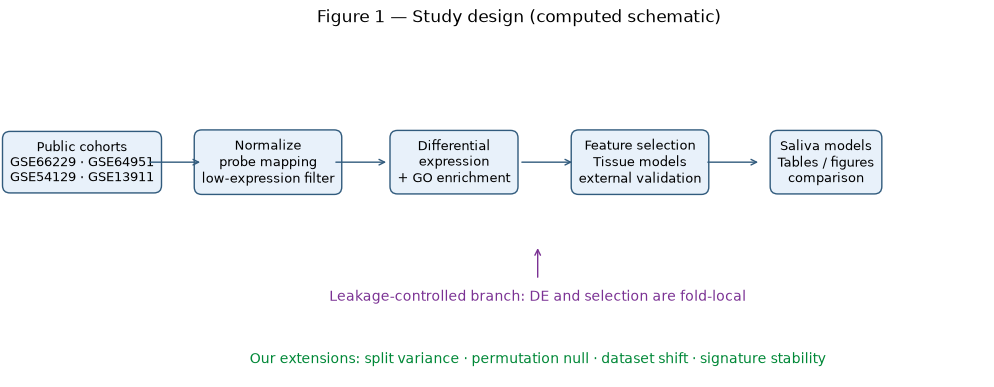

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axis("off")
boxes = [
    (0.03, "Public cohorts\nGSE66229 · GSE64951\nGSE54129 · GSE13911"),
    (0.23, "Normalize\nprobe mapping\nlow-expression filter"),
    (0.43, "Differential\nexpression\n+ GO enrichment"),
    (0.63, "Feature selection\nTissue models\nexternal validation"),
    (0.83, "Saliva models\nTables / figures\ncomparison"),
]
for x, label in boxes:
    ax.text(x, 0.62, label, ha="center", va="center", fontsize=9,
            bbox={"boxstyle": "round,pad=0.6", "facecolor": "#e8f1fa", "edgecolor": "#315b7d"},
            transform=ax.transAxes)
for left, right in zip([b[0] for b in boxes[:-1]], [b[0] for b in boxes[1:]], strict=True):
    ax.annotate("", xy=(right - 0.07, 0.62), xytext=(left + 0.07, 0.62),
                xycoords=ax.transAxes, arrowprops={"arrowstyle": "->", "color": "#315b7d"})
ax.text(0.52, 0.22, "Leakage-controlled branch: DE and selection are fold-local",
        ha="center", transform=ax.transAxes, color="#7b3294")
ax.annotate("", xy=(0.52, 0.38), xytext=(0.52, 0.28), xycoords=ax.transAxes,
            arrowprops={"arrowstyle": "->", "color": "#7b3294"})
ax.text(0.52, 0.04, "Our extensions: split variance · permutation null · dataset shift · signature stability",
        ha="center", transform=ax.transAxes, color="#008837")
ax.set_title("Figure 1 — Study design (computed schematic)")
export_figure(fig, "fig1_study_design.png")
plt.show()

**Published vs reproduced:** cohort identities and metadata counts are audited; the full raw tissue experiment and model path are not yet reproduced. **REPORT.md verdict:** sample counts partially reproduced; numerical replication remains partial.

## Data — cohort audit

**Computed metadata vs Published (reference).** The checked-in sample manifests permit an offline audit of included classes; this does not imply tissue expression processing is complete.

In [4]:
cohort_rows = []
for accession, published_classes in COHORTS.items():
    computed_manifest = RESULTS_DIR / accession / "manifest.csv"
    manifest_path = computed_manifest if RUN_MODE != "reference" and computed_manifest.is_file() else REFERENCE_DIR / "acquisition" / accession / "manifest.csv"
    manifest = pd.read_csv(manifest_path)
    included = manifest.loc[manifest.included.astype(str).str.lower() == "true"]
    computed = included.label.value_counts().to_dict()
    cohort_rows.append({
        "Dataset": accession,
        "Published GC / control": f"{published_classes[1]} / {published_classes[0]}",
        "Computed metadata GC / control": f"{computed.get(1, computed.get('1', 0))} / {computed.get(0, computed.get('0', 0))}",
    })
display(pd.DataFrame(cohort_rows))
display(Markdown("**Published vs reproduced:** all four metadata class counts match; raw tissue processing is still pending. **REPORT.md verdict:** metadata counts partially reproduced; tissue normalization and DE not reproduced."))

,Dataset,Published GC / control,Computed metadata GC / control
0,GSE66229,300 / 100,300 / 100
1,GSE64951,63 / 31,63 / 31
2,GSE54129,111 / 21,111 / 21
3,GSE13911,38 / 31,38 / 31


**Published vs reproduced:** all four metadata class counts match; raw tissue processing is still pending. **REPORT.md verdict:** metadata counts partially reproduced; tissue normalization and DE not reproduced.

## Data and differential-expression counts — Figure 2

**Computed and Published (reference).** Tissue computed counts are unavailable until normalization and DE finish. The saliva comparison and its three declared median-filter rules are computed from the checked-in summary files.

**Published reference and computed counts**

,Dataset,Count stage,Published (reference),Computed
0,GSE66229,Mapped genes,21367,not yet computed
1,GSE66229,After low-expression filter,14782,not yet computed
2,GSE66229,DEGs,1302,not yet computed
3,GSE64951,Mapped genes,21367,20953
4,GSE64951,After low-expression filter,20407,20527
5,GSE64951,DEGs,14,37


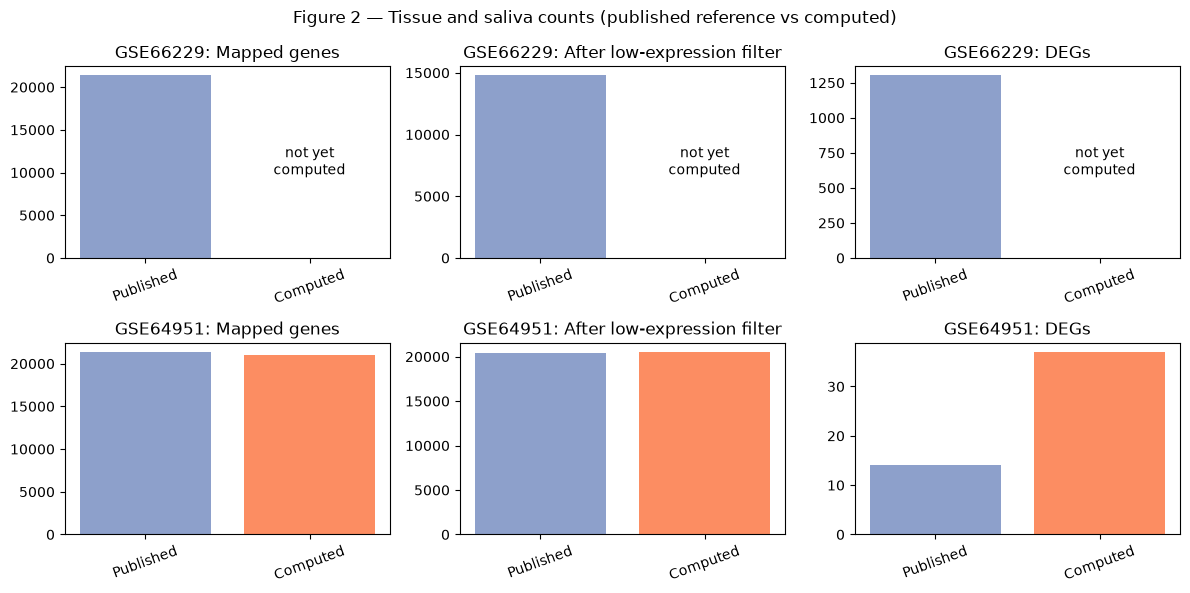

,rule,retained_genes
0,any_above_median,20527
1,mean_above_median,11171
2,half_above_median,10014


Published post-filter count: 20,407; computed filter variants: any=20,527, mean=11,171, half=10,014.


**Tissue placeholder: run `gastric-repro normalise` and `gastric-repro de`.** Published vs reproduced: saliva has 20,953 mapped genes, 20,527 filtered genes, and 37 DEGs (published: 21,367 / 20,407 / 14). **REPORT.md verdict:** saliva partially reproduced; tissue status is shown above.

In [5]:
steps = ["genes_before_filter", "genes_retained", "degs"]
step_labels = ["Mapped genes", "After low-expression filter", "DEGs"]
published_counts = {
    "GSE66229": [21367, 14782, 1302],
    "GSE64951": [21367, 20407, 14],
}
computed_counts = {"GSE66229": [None, None, None],
                   "GSE64951": [summary["genes_mapped"], summary["genes_retained"], summary["degs"]]}
gene_count_file = RESULTS_DIR / "gene_counts.csv"
if RUN_MODE != "reference" and gene_count_file.is_file():
    full_counts = pd.read_csv(gene_count_file).set_index("dataset")
    for accession in computed_counts:
        if accession in full_counts.index:
            computed_counts[accession] = [int(full_counts.loc[accession, column]) for column in steps]
count_table = pd.DataFrame([
    {"Dataset": accession, "Count stage": label,
     "Published (reference)": published_counts[accession][i],
     "Computed": computed_counts[accession][i] if computed_counts[accession][i] is not None else "not yet computed"}
    for accession in published_counts for i, label in enumerate(step_labels)
])
display(Markdown("**Reduced run – not paper-faithful**" if RUN_MODE == "reduced" else "**Published reference and computed counts**"))
display(count_table)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for row, accession in enumerate(published_counts):
    for column, label in enumerate(step_labels):
        axis = axes[row, column]
        value = computed_counts[accession][column]
        axis.bar(["Published", "Computed"],
                 [published_counts[accession][column], value or 0],
                 color=["#8da0cb", "#fc8d62"])
        if value is None:
            axis.text(1, 0.5, "not yet\ncomputed", ha="center", va="center", transform=axis.get_xaxis_transform())
        axis.set_title(f"{accession}: {label}")
        axis.tick_params(axis="x", rotation=20)
fig.suptitle("Figure 2 — Tissue and saliva counts (published reference vs computed)")
fig.tight_layout()
export_figure(fig, "fig2_gene_counts.png")
plt.show()

filter_path = stage_artifact("GSE64951", "filter_sensitivity.csv")
filter_sensitivity = pd.read_csv(filter_path) if filter_path else pd.read_csv(REFERENCE_DIR / "computed/GSE64951/filter_sensitivity.csv")
display(filter_sensitivity[["rule", "retained_genes"]])
if RUN_MODE == "reference":
    print("Published post-filter count: 20,407; computed filter variants: any=20,527, mean=11,171, half=10,014.")
else:
    print("Published post-filter count: 20,407; computed filter variants from the selected output directory.")
tissue_status = "Tissue counts are computed from the selected output directory." if all(value is not None for value in computed_counts["GSE66229"]) else "Tissue placeholder: run `gastric-repro normalise` and `gastric-repro de`."
saliva_values = computed_counts["GSE64951"]
display(Markdown(f"**{tissue_status}** Published vs reproduced: saliva has {saliva_values[0]:,} mapped genes, {saliva_values[1]:,} filtered genes, and {saliva_values[2]:,} DEGs (published: 21,367 / 20,407 / 14). **REPORT.md verdict:** saliva partially reproduced; tissue status is shown above."))

## Differential expression — Figure 3

### Figure 3A — tissue DEG heatmap

If tissue DE artifacts exist in the selected results directory, the computed heatmap is shown below. Otherwise, **not yet computed:** run `gastric-repro normalise`, then `gastric-repro de`. **Published vs reproduced:** published tissue count is 1,302 DEGs; reference mode has no computed tissue DE. **REPORT.md verdict:** not reproduced.

In [6]:
tissue_heatmap = stage_artifact("GSE66229", "heatmap.png")
if tissue_heatmap:
    display(Markdown("**Reduced run – not paper-faithful**" if RUN_MODE == "reduced" else "**Computed tissue heatmap**"))
    display(Image(filename=str(tissue_heatmap)))
else:
    display(Markdown("**Not yet computed.** Run `gastric-repro normalise`, then `gastric-repro de`."))

**Not yet computed.** Run `gastric-repro normalise`, then `gastric-repro de`.

### Figure 3B — tissue volcano plot

If tissue DE artifacts exist in the selected results directory, the computed volcano is shown below. Otherwise, **not yet computed:** run `gastric-repro normalise`, then `gastric-repro de`. No published plot is substituted for a computed one. **Published vs reproduced:** 1,302 tissue DEGs are published; reference mode has no computed tissue DE. **REPORT.md verdict:** not reproduced.

In [7]:
tissue_volcano = stage_artifact("GSE66229", "volcano.png")
if tissue_volcano:
    display(Markdown("**Reduced run – not paper-faithful**" if RUN_MODE == "reduced" else "**Computed tissue volcano**"))
    display(Image(filename=str(tissue_volcano)))
else:
    display(Markdown("**Not yet computed.** Run `gastric-repro normalise`, then `gastric-repro de`."))

**Not yet computed.** Run `gastric-repro normalise`, then `gastric-repro de`.

### Figure 3C — saliva DEG heatmap

**Computed (checked-in image).** This is the saved row-z-scored saliva heatmap for 37 computed DEGs. The available image preserves sample IDs but does not cluster rows/samples or display a class annotation track; it is not presented as a paper-faithful clustered heatmap.

**Computed saliva heatmap**

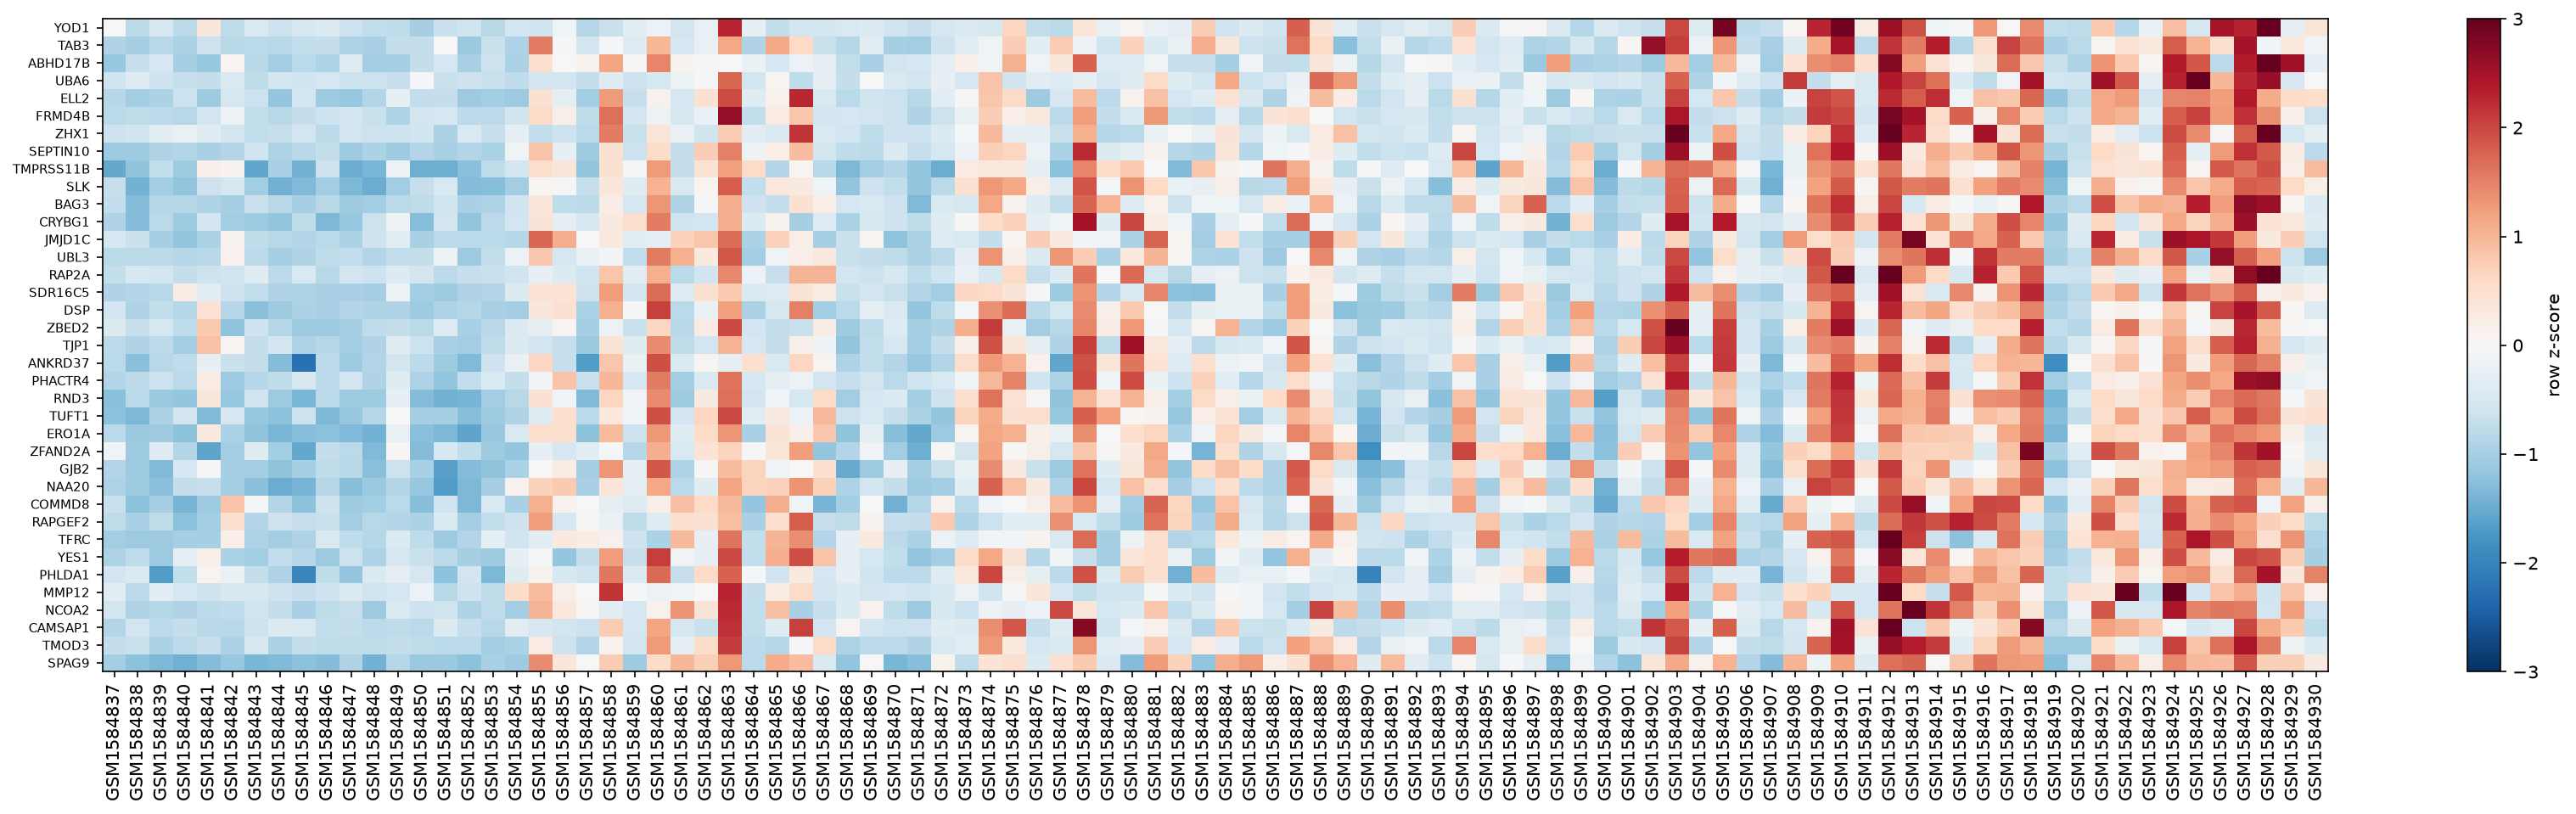

The saved heatmap is row-z-scored but does not cluster rows/samples or include a class annotation track. **Published vs reproduced:** saliva DE is partially reproduced. **REPORT.md verdict:** partially reproduced.

In [8]:
heatmap_source = stage_artifact("GSE64951", "heatmap.png")
if heatmap_source:
    display(Markdown("**Reduced run – not paper-faithful**" if RUN_MODE == "reduced" else "**Computed saliva heatmap**"))
    display(Image(filename=str(heatmap_source)))
    if EXPORT_FIGURES:
        shutil.copyfile(heatmap_source, EXPORT_DIR / "fig3c_heatmap_saliva.png")
else:
    display(Markdown("**Not yet computed:** run `gastric-repro normalise`, then `gastric-repro de`."))
display(Markdown("The saved heatmap is row-z-scored but does not cluster rows/samples or include a class annotation track. **Published vs reproduced:** saliva DE is partially reproduced. **REPORT.md verdict:** partially reproduced."))

### Figure 3D — saliva volcano plot

**Computed (checked-in image) plus labelled DEG comparison.** The stored volcano uses the complete filtered gene universe. The second view uses only the 37 stored DEG rows, so it distinguishes and labels the 14 published genes and 23 additional genes without implying that the subset is a full volcano background.

**Computed full-universe volcano**

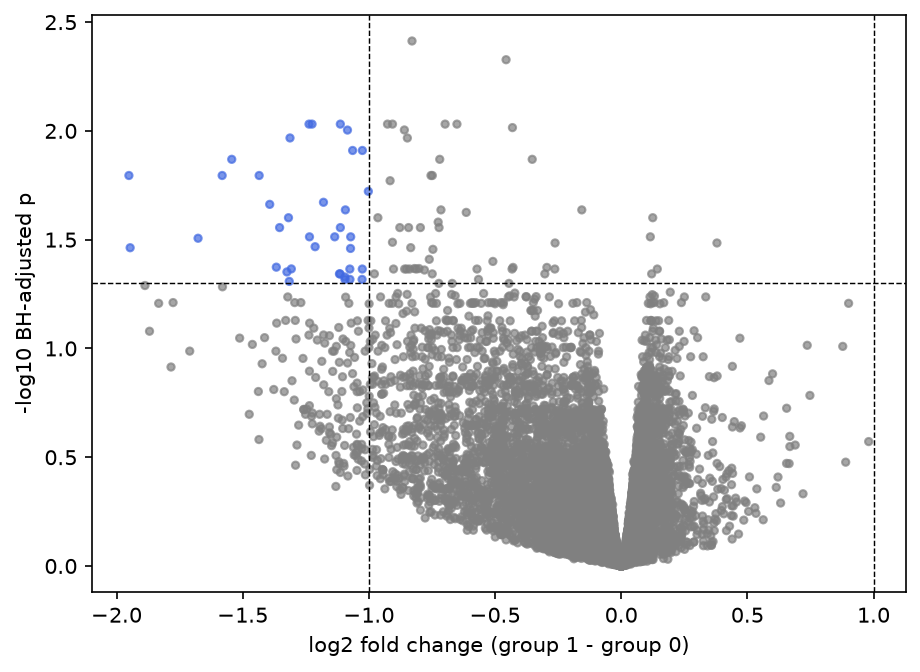

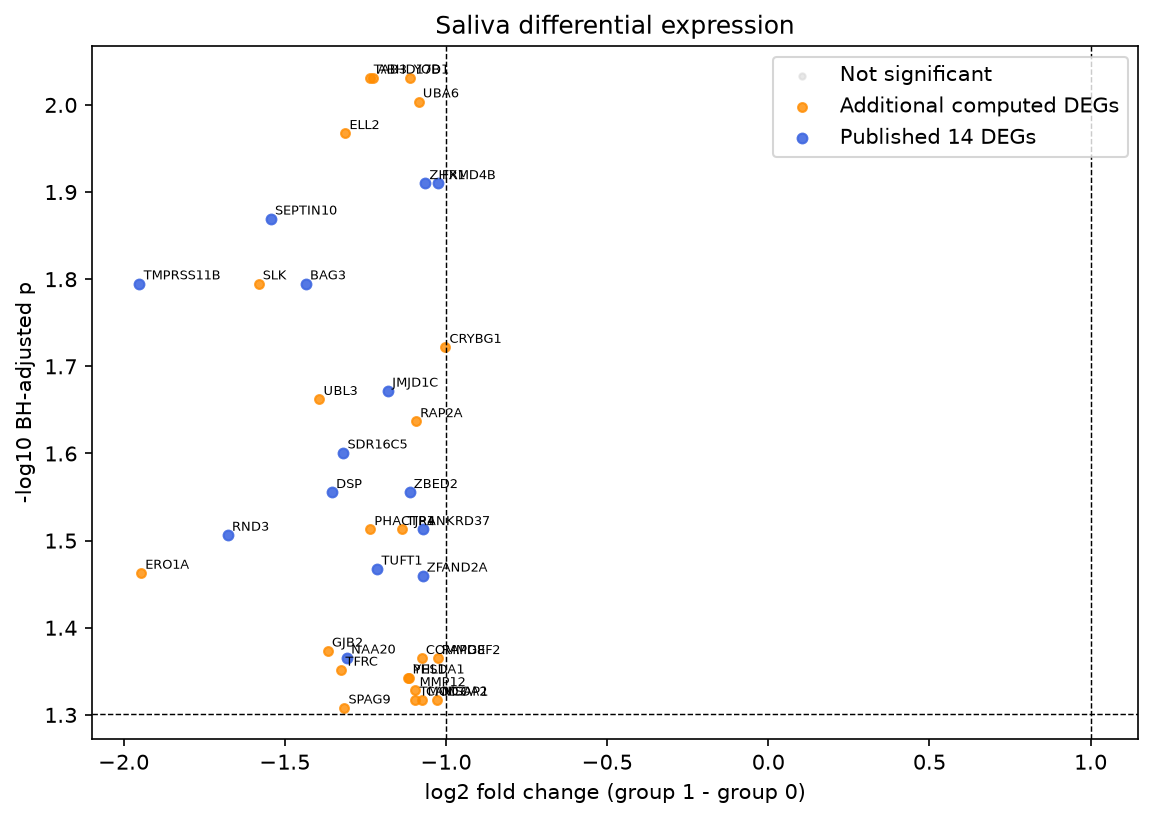

**Published vs reproduced:** 14/14 published DEGs recovered; 23 additional computed DEGs. **REPORT.md verdict:** partially reproduced.

In [9]:
volcano_source = stage_artifact("GSE64951", "volcano.png")
degs_source = stage_artifact("GSE64951", "degs.csv")
if volcano_source and degs_source:
    display(Markdown("**Reduced run – not paper-faithful**" if RUN_MODE == "reduced" else "**Computed full-universe volcano**"))
    display(Image(filename=str(volcano_source)))
    if EXPORT_FIGURES:
        shutil.copyfile(volcano_source, EXPORT_DIR / "fig3d_volcano_saliva_full.png")
    saliva_degs = pd.read_csv(degs_source, index_col="gene")
else:
    display(Markdown("**Not yet computed:** run `gastric-repro normalise`, then `gastric-repro de`."))
    saliva_degs = pd.read_csv(REFERENCE_DIR / "computed/GSE64951/degs.csv", index_col="gene")
plot_path = Path("/tmp/lopes2025_saliva_deg_volcano.png")
plot_saliva_deg_volcano(saliva_degs, plot_path, published_genes=list(SALIVA_GENES))
display(Image(filename=str(plot_path)))
if EXPORT_FIGURES:
    plot_saliva_deg_volcano(saliva_degs, EXPORT_DIR / "fig3d_volcano_saliva.png",
                            published_genes=list(SALIVA_GENES))
recovered_count = len(set(SALIVA_GENES) & set(saliva_degs.index.astype(str)))
additional_count = len(set(saliva_degs.index.astype(str)) - set(SALIVA_GENES))
display(Markdown(f"**Published vs reproduced:** {recovered_count}/14 published DEGs recovered; {additional_count} additional computed DEGs. **REPORT.md verdict:** partially reproduced."))

## Enrichment — Figures 4A–4E

**Published (reference) terms:** tissue: “cell cycle” and “mitotic cell cycle process”; saliva: “membrane”, “cell periphery”, “hydrolase activity”, “nucleotide binding”, “purine nucleotide binding”, and “small molecule binding”.

In [10]:
go_targets = pd.DataFrame([
    ("Tissue", "cell cycle; mitotic cell cycle process"),
    ("Saliva", "membrane; cell periphery; hydrolase activity; nucleotide binding; purine nucleotide binding; small molecule binding"),
], columns=["Cohort", "Published GO terms (reference)"])
display(go_targets)
for item, stage in (
    ("Figure 4A — tissue GSEA dot plot", "gastric-repro enrichment"),
    ("Figure 4D — saliva GSEA dot plot", "gastric-repro enrichment"),
    ("Figures 4B and 4E — tissue/saliva enrichment maps", "gastric-repro enrichment"),
    ("Figure 4C — tissue semantic reduction (rrvgo-style approximation)", "gastric-repro enrichment"),
):
    display(Markdown(f"**{item}: not yet computed.** Run `{stage}`. The Python semantic-reduction approximation is also not yet implemented; no rrvgo result is claimed."))
display(Markdown("**Published vs reproduced:** no GSEA results are checked in. `gseapy` permutation FDR would not be equivalent to `clusterProfiler` adjusted P values. **REPORT.md verdict:** not reproduced."))

,Cohort,Published GO terms (reference)
0,Tissue,cell cycle; mitotic cell cycle process
1,Saliva,membrane; cell periphery; hydrolase activity; ...


**Figure 4A — tissue GSEA dot plot: not yet computed.** Run `gastric-repro enrichment`. The Python semantic-reduction approximation is also not yet implemented; no rrvgo result is claimed.

**Figure 4D — saliva GSEA dot plot: not yet computed.** Run `gastric-repro enrichment`. The Python semantic-reduction approximation is also not yet implemented; no rrvgo result is claimed.

**Figures 4B and 4E — tissue/saliva enrichment maps: not yet computed.** Run `gastric-repro enrichment`. The Python semantic-reduction approximation is also not yet implemented; no rrvgo result is claimed.

**Figure 4C — tissue semantic reduction (rrvgo-style approximation): not yet computed.** Run `gastric-repro enrichment`. The Python semantic-reduction approximation is also not yet implemented; no rrvgo result is claimed.

**Published vs reproduced:** no GSEA results are checked in. `gseapy` permutation FDR would not be equivalent to `clusterProfiler` adjusted P values. **REPORT.md verdict:** not reproduced.

## Feature selection — Figure S1

**Published (reference) tissue signature:** CDH3, DKC1, ESM1, MUSTN1, RCC2, TMT1A, VEGFD.

In [11]:
display(pd.DataFrame({"Published tissue genes (reference)": list(TISSUE_GENES)}))
display(Markdown("**Figure S1: not yet computed.** RF/GBM/DT feature-importance values and selected genes require tissue DE and model fitting. Run `gastric-repro ml` after normalization and DE. The package's automated selection rule is an explicit approximation to the paper's unspecified visual/importance selection. **REPORT.md verdict:** not reproduced."))

,Published tissue genes (reference)
0,CDH3
1,DKC1
2,ESM1
3,MUSTN1
4,RCC2
5,TMT1A
6,VEGFD


**Figure S1: not yet computed.** RF/GBM/DT feature-importance values and selected genes require tissue DE and model fitting. Run `gastric-repro ml` after normalization and DE. The package's automated selection rule is an explicit approximation to the paper's unspecified visual/importance selection. **REPORT.md verdict:** not reproduced.

## Internal tissue models — Figure 5A–5E and Table 1

**Published (reference) Table 1** values are shown separately from computed results. ROC curves, AUC confidence intervals, threshold-0.5 confusion matrices, and computed metric deltas are not available until the ML stage completes.

In [12]:
metric_targets = pd.read_csv(REFERENCE_DIR / "publication/metric_targets.csv")
computed_comparison_path = ACTIVE_RESULTS / "all_published_metric_comparison.csv"
def show_article_table(table_id):
    targets = metric_targets.loc[metric_targets.source_table == table_id].copy()
    targets = targets[["dataset", "model", "metric", "published_text", "published_interval_valid"]]
    targets["published_text"] = targets.published_text.fillna("missing in source")
    targets = targets.rename(columns={"published_text": "Published (reference)",
                                      "published_interval_valid": "Published CI valid"})
    targets["Computed"] = "not available"
    targets["Delta"] = "not available"
    if computed_comparison_path.is_file():
        computed = pd.read_csv(computed_comparison_path)
        computed = computed.loc[computed.source_table == table_id]
        keys = ["dataset", "model", "metric"]
        if "computed_estimate" in computed:
            values = computed[keys + ["computed_estimate", "computed_lower", "computed_upper", "estimate_difference"]]
            values = values.rename(columns={"computed_estimate": "Computed estimate",
                                            "computed_lower": "Computed CI lower",
                                            "computed_upper": "Computed CI upper",
                                            "estimate_difference": "Delta"})
            targets = targets.merge(values, on=keys, how="left")
    return targets

display(show_article_table("Tab1"))
display(Markdown("**Figures 5A–5E: not yet computed.** Run `gastric-repro ml` after tissue preprocessing. Table 1's reversed SVM NPV interval is preserved and flagged by `Published CI valid=False`; no interval is repaired. **Published vs reproduced:** reference transcription only, no computed metrics. **REPORT.md verdict:** not reproduced."))

,dataset,model,metric,Published (reference),Published CI valid,Computed,Delta
0,GSE66229,RF,sensitivity,0.944 (0.889–0.989),True,not available,not available
1,GSE66229,RF,specificity,0.967 (0.900-1.000),True,not available,not available
2,GSE66229,RF,ppv,0.988 (0.966-1.000),True,not available,not available
3,GSE66229,RF,npv,0.853 (0.744–0.967),True,not available,not available
4,GSE66229,RF,accuracy,0.950 (0.908–0.983),True,not available,not available
5,GSE66229,RF,auc,0.988 (0.966-1.000),True,not available,not available
6,GSE66229,SVM,sensitivity,0.944 (0.900-0.989),True,not available,not available
7,GSE66229,SVM,specificity,0.933 (0.833-1.000),True,not available,not available
8,GSE66229,SVM,ppv,0.977 (0.945-1.000),True,not available,not available
9,GSE66229,SVM,npv,0.848 (0.852 − 0.750),False,not available,not available


**Figures 5A–5E: not yet computed.** Run `gastric-repro ml` after tissue preprocessing. Table 1's reversed SVM NPV interval is preserved and flagged by `Published CI valid=False`; no interval is repaired. **Published vs reproduced:** reference transcription only, no computed metrics. **REPORT.md verdict:** not reproduced.

## External tissue validation — Figure 6A–6J and Table 2

Models must be applied directly to GSE54129 and GSE13911 without retraining. The target cohort labels are used for evaluation, not fitting.

In [13]:
display(show_article_table("Tab2"))
display(Markdown("**Figures 6A–6J: not yet computed.** Run `gastric-repro ml` after tissue preprocessing. Table 2's missing GSE13911 SVM NPV remains missing, not zero. **Published vs reproduced:** published targets only. **REPORT.md verdict:** not reproduced."))

,dataset,model,metric,Published (reference),Published CI valid,Computed,Delta
24,GSE54129,RF,sensitivity,0.405 (0.315–0.486),True,not available,not available
25,GSE54129,RF,specificity,0.905 (0.762-1.000),True,not available,not available
26,GSE54129,RF,ppv,0.957 (0.894-1.000),True,not available,not available
27,GSE54129,RF,npv,0.224 (0.186–0.259),True,not available,not available
28,GSE54129,RF,accuracy,0.485 (0.402–0.553),True,not available,not available
29,GSE54129,RF,auc,0.843 (0.725–0.935),True,not available,not available
30,GSE54129,SVM,sensitivity,0.910 (0.856–0.955),True,not available,not available
31,GSE54129,SVM,specificity,0.762 (0.571–0.952),True,not available,not available
32,GSE54129,SVM,ppv,0.953 (0.917–0.990),True,not available,not available
33,GSE54129,SVM,npv,0.615 (0.480–0.783),True,not available,not available


**Figures 6A–6J: not yet computed.** Run `gastric-repro ml` after tissue preprocessing. Table 2's missing GSE13911 SVM NPV remains missing, not zero. **Published vs reproduced:** published targets only. **REPORT.md verdict:** not reproduced.

## Tissue models applied to saliva — Figure S2

**Not yet computed.** Directly apply tissue-trained models to all saliva samples; do not retrain. Run `gastric-repro ml` after all cohort preprocessing. The published AUC is approximately 0.5 and is a reference only. **REPORT.md verdict:** not reproduced.

## Saliva models — Figure 7A–7E and Table 3

Both saliva panels are reported separately: the 14 published genes for like-for-like comparison and all discovered DEGs. The pipeline can now select either panel explicitly with `--saliva-gene-set`; use separate output directories for separate runs.

In [14]:
display(Markdown("**Published panel (reference):** " + ", ".join(SALIVA_GENES)))
display(Markdown("**Computed discovered panel:** " + ", ".join(saliva_degs.index.astype(str))))
for label, setting in (("Published 14 genes", "published"), ("Discovered DEGs", "discovered")):
    model_file = (PUBLISHED_SALIVA_RESULTS_DIR if setting == "published" else ACTIVE_RESULTS) / "GSE64951/models/holdout_predictions.csv"
    if RUN_MODE != "reference" and model_file.is_file():
        display(Markdown(f"**{label} — Computed:** model predictions are available at `{model_file}`. ROC/confusion plots are not stored by the pipeline."))
    else:
        display(Markdown(f"**{label} — not yet computed.** Run `gastric-repro ml --saliva-gene-set {setting} --output <separate-results-dir>` after all cohort preprocessing. Reduced-mode outputs are not paper-faithful."))
display(show_article_table("Tab3"))
display(Markdown("**Figures 7A–7E:** no ROC/confusion plots are checked in. **Table 3:** published targets are reference only; computed CIs and deltas require the two ML runs. **Published vs reproduced:** no saliva model metrics reproduced. **REPORT.md verdict:** not reproduced."))

**Published panel (reference):** ANKRD37, BAG3, DSP, FRMD4B, JMJD1C, NAA20, RND3, SDR16C5, SEPTIN10, TMPRSS11B, TUFT1, ZBED2, ZFAND2A, ZHX1

**Computed discovered panel:** ABHD17B, ANKRD37, BAG3, CAMSAP1, COMMD8, CRYBG1, DSP, ELL2, ERO1A, FRMD4B, GJB2, JMJD1C, MMP12, NAA20, NCOA2, PHACTR4, PHLDA1, RAP2A, RAPGEF2, RND3, SDR16C5, SEPTIN10, SLK, SPAG9, TAB3, TFRC, TJP1, TMOD3, TMPRSS11B, TUFT1, UBA6, UBL3, YES1, YOD1, ZBED2, ZFAND2A, ZHX1

**Published 14 genes — not yet computed.** Run `gastric-repro ml --saliva-gene-set published --output <separate-results-dir>` after all cohort preprocessing. Reduced-mode outputs are not paper-faithful.

**Discovered DEGs — not yet computed.** Run `gastric-repro ml --saliva-gene-set discovered --output <separate-results-dir>` after all cohort preprocessing. Reduced-mode outputs are not paper-faithful.

,dataset,model,metric,Published (reference),Published CI valid,Computed,Delta
72,GSE64951,RF,sensitivity,0.684 (0.474–0.895),True,not available,not available
73,GSE64951,RF,specificity,0.800 (0.500-1.000),True,not available,not available
74,GSE64951,RF,ppv,0.867 (0.722-1.000),True,not available,not available
75,GSE64951,RF,npv,0.571 (0.421-0.800),True,not available,not available
76,GSE64951,RF,accuracy,0.724 (0.586–0.897),True,not available,not available
77,GSE64951,RF,auc,0.842 (0.679–0.963),True,not available,not available
78,GSE64951,SVM,sensitivity,0.790 (0.579–0.947),True,not available,not available
79,GSE64951,SVM,specificity,0.700 (0.400–0.900),True,not available,not available
80,GSE64951,SVM,ppv,0.833 (0.700-0.947),True,not available,not available
81,GSE64951,SVM,npv,0.636 (0.429–0.889),True,not available,not available


**Figures 7A–7E:** no ROC/confusion plots are checked in. **Table 3:** published targets are reference only; computed CIs and deltas require the two ML runs. **Published vs reproduced:** no saliva model metrics reproduced. **REPORT.md verdict:** not reproduced.

## Best model by dataset — Table 4

**Published (reference) vs computed:** Table 4 is transcribed below. Computed best-model rows are available only after models run; source intervals are not reconciled against Table 1.

In [15]:
display(show_article_table("Tab4"))
display(Markdown("The differing RF AUC intervals in Table 1 and Table 4 remain separate published targets. **Computed Table 4 and deltas: not yet available; run `gastric-repro ml`. REPORT.md verdict:** not reproduced."))

,dataset,model,metric,Published (reference),Published CI valid,Computed,Delta
96,GSE66229,RF,sensitivity,0.944 (0.889–0.989),True,not available,not available
97,GSE66229,RF,specificity,0.967 (0.900-1.000),True,not available,not available
98,GSE66229,RF,auc,0.988 (0.973-1.000),True,not available,not available
99,GSE54129,SVM,sensitivity,0.910 (0.856–0.955),True,not available,not available
100,GSE54129,SVM,specificity,0.762 (0.571–0.952),True,not available,not available
101,GSE54129,SVM,auc,0.857 (0.757–0.935),True,not available,not available
102,GSE13911,RF,sensitivity,0.737 (0.579–0.868),True,not available,not available
103,GSE13911,RF,specificity,0.968 (0.903-1.000),True,not available,not available
104,GSE13911,RF,auc,0.913 (0.834–0.972),True,not available,not available
105,GSE64951,SVM,sensitivity,0.790 (0.579–0.947),True,not available,not available


The differing RF AUC intervals in Table 1 and Table 4 remain separate published targets. **Computed Table 4 and deltas: not yet available; run `gastric-repro ml`. REPORT.md verdict:** not reproduced.

## Our extensions — not part of the paper's analysis

These are explicitly separated from the paper-like results. They remain placeholders until their output files exist.

In [16]:
extensions = [
    ("Leakage: paper-like full-cohort DE vs fold-local DE", "gastric-repro robustness"),
    ("Split variance: AUC distribution and first-place frequency", "gastric-repro robustness"),
    ("Permutation null: AUC histograms and observed value", "gastric-repro robustness"),
    ("Dataset shift: direct validation vs target standardisation", "gastric-repro robustness"),
    ("Signature stability: selection frequency by gene", "gastric-repro robustness"),
]
for title, stage in extensions:
    display(Markdown(f"**{title}: not yet computed.** Run `{stage}` after the corresponding model stages. These are our extensions, not published results."))
display(Markdown("**Published vs reproduced:** no cohort-scale robustness results are checked in. **REPORT.md verdict:** not reproduced."))

**Leakage: paper-like full-cohort DE vs fold-local DE: not yet computed.** Run `gastric-repro robustness` after the corresponding model stages. These are our extensions, not published results.

**Split variance: AUC distribution and first-place frequency: not yet computed.** Run `gastric-repro robustness` after the corresponding model stages. These are our extensions, not published results.

**Permutation null: AUC histograms and observed value: not yet computed.** Run `gastric-repro robustness` after the corresponding model stages. These are our extensions, not published results.

**Dataset shift: direct validation vs target standardisation: not yet computed.** Run `gastric-repro robustness` after the corresponding model stages. These are our extensions, not published results.

**Signature stability: selection frequency by gene: not yet computed.** Run `gastric-repro robustness` after the corresponding model stages. These are our extensions, not published results.

**Published vs reproduced:** no cohort-scale robustness results are checked in. **REPORT.md verdict:** not reproduced.